<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#Import-and-Load-Data" data-toc-modified-id="Import-and-Load-Data-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>Import and Load Data</a></span></li><li><span><a href="#Preprocessing" data-toc-modified-id="Preprocessing-2"><span class="toc-item-num">2&nbsp;&nbsp;</span>Preprocessing</a></span></li><li><span><a href="#Trying-Out-Models" data-toc-modified-id="Trying-Out-Models-3"><span class="toc-item-num">3&nbsp;&nbsp;</span>Trying Out Models & Model Evaluation</a></span><ul class="toc-item"><li><span><a href="#Logistic-Regression" data-toc-modified-id="Logistic-Regression-3.1"><span class="toc-item-num">3.1&nbsp;&nbsp;</span>Logistic Regression</a></span></li><li><span><a  href="#Tree-based Models" data-toc-modified-id="Tree-based Models -3.2"><span class="toc-item-num">3.2&nbsp;&nbsp;</span>Tree-based Models</a></span></li></ul></li><li><span><a href="#Model-Evaluation" data-toc-modified-id="Model-Evaluation-4"><span class="toc-item-num">4&nbsp;&nbsp;</span>Model Performance on Test Set</a></span></li></ul></div>

## Import and Load Data

In [ ]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Lasso, ElasticNet
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,roc_curve, classification_report,confusion_matrix, precision_recall_curve
import numpy as np
import seaborn as sns
from sklearn import metrics
import matplotlib.pyplot as plt



In [ ]:
#load in your data
df = pd.read_csv("loans.csv")
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

/var/folders/fr/y9_133rs6mn0yv6kd44lry8w0000gn/T/ipykernel_3433/4195021509.py:2: DtypeWarning: Columns (20,56) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("loans.csv")


In [ ]:
df.head()
df.shape
df.columns

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
0,1077501,1296599,5000,5000,4975.0,36 months,10.65,162.87,B,B2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1077430,1314167,2500,2500,2500.0,60 months,15.27,59.83,C,C4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1077175,1313524,2400,2400,2400.0,36 months,15.96,84.33,C,C5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1076863,1277178,10000,10000,10000.0,36 months,13.49,339.31,C,C1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1075358,1311748,3000,3000,3000.0,60 months,12.69,67.79,B,B5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


(887379, 74)

Index(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title',
       'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
       'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose',
       'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs',
       'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq',
       'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal',
       'revol_util', 'total_acc', 'initial_list_status', 'out_prncp',
       'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp',
       'total_rec_int', 'total_rec_late_fee', 'recoveries',
       'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
       'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med',
       'mths_since_last_major_derog', 'policy_code', 'application_type',
       'annual_inc_joint', 'dti_joint', 'verification_status_joint',
    

### <font color="green"> Additional Checks</font>

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 887379 entries, 0 to 887378
Data columns (total 74 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           887379 non-null  int64  
 1   member_id                    887379 non-null  int64  
 2   loan_amnt                    887379 non-null  int64  
 3   funded_amnt                  887379 non-null  int64  
 4   funded_amnt_inv              887379 non-null  float64
 5   term                         887379 non-null  object 
 6   int_rate                     887379 non-null  float64
 7   installment                  887379 non-null  float64
 8   grade                        887379 non-null  object 
 9   sub_grade                    887379 non-null  object 
 10  emp_title                    835917 non-null  object 
 11  emp_length                   842554 non-null  object 
 12  home_ownership               887379 non-null  object 
 13 

In [ ]:
df.isna().sum()

id                       0
member_id                0
loan_amnt                0
funded_amnt              0
funded_amnt_inv          0
                     ...  
all_util            866007
total_rev_hi_lim     70276
inq_fi              866007
total_cu_tl         866007
inq_last_12m        866007
Length: 74, dtype: int64

## Preprocessing
Implementing key preprocessing steps such as:
 - Define the label column
 - Handle missing values
 - Encode categorical variables, scale data (if you wish), feature selection, etc.
 - Split the dataset into features (X) and target variable (y)
 - Split into training and testing sets

In [ ]:
# Check how many unique members are in the dataset
df['member_id'].nunique()
# Check if there is any na in the column
df['member_id'].isna().sum()

887379

0

**How many loans did each borrower borrow?**


In [ ]:
df['member_id'].value_counts(ascending=True)

member_id
1296599     1
65566896    1
65527018    1
65006696    1
64936855    1
           ..
31456838    1
31436866    1
31456960    1
31516995    1
38982659    1
Name: count, Length: 887379, dtype: int64

#### **Alternatively**

In [ ]:
number_of_loans_taken = df[["id","member_id"]].groupby(by="member_id").count()
number_of_loans_taken = number_of_loans_taken.rename(columns={"id": "number of loans taken"})
number_of_loans_taken
#number_of_loans_taken.max()

,number of loans taken
member_id,
70473,1
70626,1
70651,1
70681,1
70694,1
...,...
73519870,1
73519894,1
73542831,1


**Define the label column for binary classification**

In [ ]:
df['loan_status'].value_counts()

loan_status
Current                                                601779
Fully Paid                                             207723
Charged Off                                             45248
Late (31-120 days)                                      11591
Issued                                                   8460
In Grace Period                                          6253
Late (16-30 days)                                        2357
Does not meet the credit policy. Status:Fully Paid       1988
Default                                                  1219
Does not meet the credit policy. Status:Charged Off       761
Name: count, dtype: int64

### **Labelling**

Define a label column named "loan_performance" based on column "loan_status", where loan_performance = 1 indicates that the borrower repaid the loan responsibly, and loan_performance = 0 indicates otherwise. Remove the rows when loan_status is Current or Issued.
Loans that are 'Full Paid' and 'Does not meet the credit policy. Status:Fully

*   Paid' were fully paid and completed. That's why the customers who borrowed the loans,can be considered as reliable. So we should label loan_performance = 1 for those.
*   "Charged Off" means a lender has declared a debt unlikely to be collected or has given up expecting to get the money back. That means the borrower still owes the money. That is why this should be considered as bad loan. So "Charged off" should be labelled with 0.
Addition to "Charged Off", we should also label "Default" 0 becuase when the loan is not paid people first get default and then get charged off. So "Default" means not paid.

In [ ]:
Late_16_30_days =(len(df[df['loan_status']== 'Late (16-30 days)']) / df.shape[0])*100 # % of Late_16_30_days
Late_31_120_days =(len(df[df['loan_status']== 'Late (31-120 days)']) / df.shape[0])*100 # % of Late_31_120_days
In_Grace_Period =(len(df[df['loan_status']== 'In Grace Period']) / df.shape[0])*100 # % of In_Grace_Period
print(f'%',round(Late_16_30_days,3), f'of the data is Late (16-30 days)')
print(f'%',round(Late_31_120_days,3), f'of the data is Late (31-120 days)')
print(f'%',round(In_Grace_Period,3), f'of the data is In Grace Period')
total_impact = Late_16_30_days + Late_31_120_days + In_Grace_Period # sum of all of them.
print(f'in total %',round(total_impact,2))

% 0.266 of the data is Late (16-30 days)
% 1.306 of the data is Late (31-120 days)
% 0.705 of the data is In Grace Period
in total % 2.28


Both <b> Late (16-30 days) & Late (31-120 days)</b> and <b> In Grace Period</b> statuses should be excluded for two main reasons:<br>
1. These are temporary statuses and in both situations we don't know what will be loan outcome <b>yet</b>
2. Both individually and total, these part of data is a very small portion of the datase, %2.28 ~ %2 which means that almost no impact  <br>
We did not want to use other features to label these loans as 0 or 1 because doing so would require making assumptions based on our own judgment, which could introduce bias into the dataset. Since these loan statuses do not represent finalized outcomes, we decided not to assign labels to them. Additionally, these observations make up a very small portion of an otherwise large dataset, so removing them is not expected to have a significant impact on the overall analysis.

In [ ]:
# status_to_remove is a list that keeps the loan status that will remove "Current" & "Issued" statuses as suggested \
# with Late (16-30 days)","Late (31-120 days)", "In Grace Period" as we decided
status_to_remove = [ "Current", "Issued","Late (16-30 days)","Late (31-120 days)", "In Grace Period"]

# rows_to_remove are the loans that are either 'Current' or 'Issued' as in the status_to_remove
rows_to_remove = df[df["loan_status"].isin(status_to_remove)]

# let's remove Current and Issued loans
df = df.drop(rows_to_remove.index)

# let's check if successfully removed
df['loan_status'].value_counts()

# Generate the loan performance by labelling fully paid and doesn not meet the credit policy by 1 and 0 the rest.
df['loan_performance'] = df['loan_status'].apply(lambda x: 1 if x in
                                                ['Fully Paid',
                                                 'Does not meet the credit policy. Status:Fully Paid ']
                                                else 0)

loan_status
Fully Paid                                             207723
Charged Off                                             45248
Does not meet the credit policy. Status:Fully Paid       1988
Default                                                  1219
Does not meet the credit policy. Status:Charged Off       761
Name: count, dtype: int64

### **Design feature set**


### **Reviewing Columns & Identifying the NA values**


In [ ]:
# lets check how many loans data we have now
df_row_num = df.shape[0]
print(f"total number of entries:", df_row_num)

# threshold is a number that represents the %80 of the data.
# We'll use it to removew NA values from the dataset
threshold = int(round(0.80 * df_row_num))
print(f"threshold:", threshold)

# valuable_columns are the columns that have more non-NA values than the threshold value
valuable_columns = df.columns[df.isna().sum()<threshold]
print(f"These columns have less than 80% missing data, so they still contain sufficient information to be included in the analysis. The columns are:\n",valuable_columns.tolist())

# let's check if this is correct
df[valuable_columns].info()

total number of entries: 256939
threshold: 205551
These columns have less than 80% missing data, so they still contain sufficient information to be included in the analysis. The columns are:
 ['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d', 'collections_12_mths_ex_med', 'policy_code', 'application_type', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_b


### **Cleaning up the dataset & Selecting the features**


In [ ]:
df.columns

Index(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title',
       'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
       'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose',
       'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs',
       'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq',
       'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal',
       'revol_util', 'total_acc', 'initial_list_status', 'out_prncp',
       'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp',
       'total_rec_int', 'total_rec_late_fee', 'recoveries',
       'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
       'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med',
       'mths_since_last_major_derog', 'policy_code', 'application_type',
       'annual_inc_joint', 'dti_joint', 'verification_status_joint',
    

In [ ]:
# let's keep only valuable columns for now
# not to loose any data we'll create a copy of the original
df_cleaned = df.loc[:,valuable_columns].copy()

<font color= 'purple'> <b>
    Generating a new parameter from earliest_cr_line and issue_d columns
</font>

In [ ]:
# Handling the Date features
df_cleaned['earliest_cr_line_dt'] = pd.to_datetime(df_cleaned['earliest_cr_line'], format='%b-%Y', errors='coerce')
df_cleaned['issue_d_dt'] = pd.to_datetime(df_cleaned['issue_d'], format='%b-%Y', errors='coerce')
# credit_hist_months = issue date - earliest credit line, which represents what was the credit history when the loan was requested
df_cleaned['credit_hist_months'] = (
    (df_cleaned['issue_d_dt'].dt.year - df_cleaned['earliest_cr_line_dt'].dt.year) * 12 +
    (df_cleaned['issue_d_dt'].dt.month - df_cleaned['earliest_cr_line_dt'].dt.month)
)

<font color ='purple'> <b>
Grouping purpose column
</font>

<Figure size 800x400 with 0 Axes>

<Axes: xlabel='purpose', ylabel='count'>

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13],
 [Text(0, 0, 'debt_consolidation'),
  Text(1, 0, 'credit_card'),
  Text(2, 0, 'home_improvement'),
  Text(3, 0, 'other'),
  Text(4, 0, 'major_purchase'),
  Text(5, 0, 'small_business'),
  Text(6, 0, 'car'),
  Text(7, 0, 'medical'),
  Text(8, 0, 'moving'),
  Text(9, 0, 'wedding'),
  Text(10, 0, 'house'),
  Text(11, 0, 'vacation'),
  Text(12, 0, 'educational'),
  Text(13, 0, 'renewable_energy')])

Text(0.5, 1.0, 'Loan Purpose Distribution (Before Grouping)')

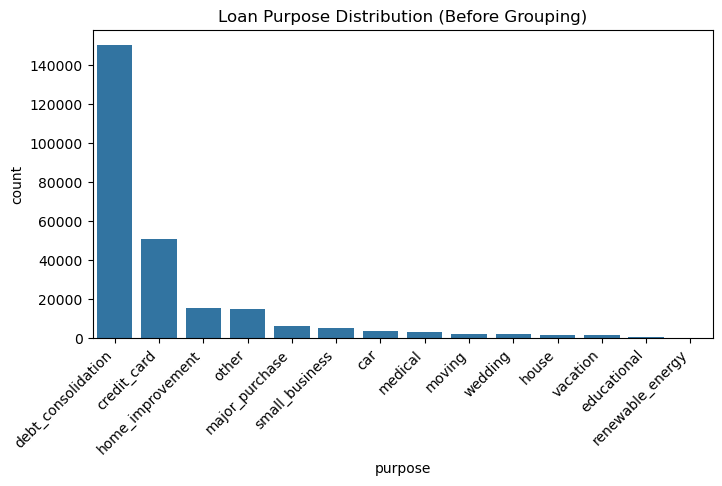

In [ ]:
# Set the size of the figure (width, height) so labels don't overlap
plt.figure(figsize=(8,4))

# Create the countplot
# 'order' sorts the bars from biggest to smallest
sns.countplot(x='purpose', data=df, order=df['purpose'].value_counts().index)

# Rotate the labels so they are readable
plt.xticks(rotation=45, ha='right')

# Add titles
plt.title('Loan Purpose Distribution (Before Grouping)')
plt.show()

<font color='blue'> <b> Observation:</font>
As it's shown above Top 2-3 purposes taking the majority of loans. To be able to work with the data easily we need to redefine this column. Otherwise we are going to en up with too many unnecessary column in the one hot encoding part.

In [ ]:
# Define the categories to keep
purpose_categories = ['debt_consolidation', 'credit_card', 'home_improvement']

# if it's not one of the 3 purpose lable as 'other'
df_cleaned['purpose'] = df_cleaned['purpose'].apply(lambda x: x if x in purpose_categories else 'other')

# 3. Check your new counts
print(df_cleaned['purpose'].value_counts())

debt_consolidation    150253
credit_card            50649
other                  40847
home_improvement       15190
Name: purpose, dtype: int64


<font color ='purple'> <b>
Grouping home_ownership column
</font>

<Figure size 800x400 with 0 Axes>

<Axes: xlabel='home_ownership', ylabel='count'>

Text(0.5, 1.0, 'Home Ownership Distribution (Before Grouping)')

Text(0.5, 0, 'Home Ownership Type')

Text(0, 0.5, 'Count')

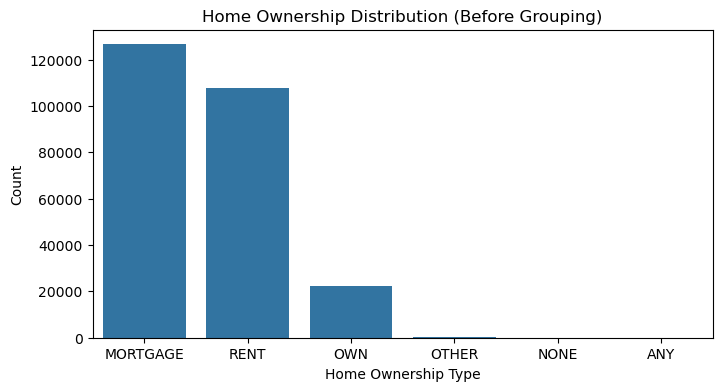

In [ ]:
# Set the size of the figure
plt.figure(figsize=(8, 4))

# Create the countplot
# 'order' sorts the bars from biggest to smallest
sns.countplot(x='home_ownership', data=df_cleaned, order=df_cleaned['home_ownership'].value_counts().index)

# Add titles and labels
plt.title('Home Ownership Distribution (Before Grouping)')
plt.xlabel('Home Ownership Type')
plt.ylabel('Count')

plt.show()

In [ ]:
df_cleaned['home_ownership'].value_counts()

MORTGAGE    126598
RENT        107831
OWN          22282
OTHER          179
NONE            48
ANY              1
Name: home_ownership, dtype: int64

<font color='blue'> <b> Observation:</b></font>
As shown above, MORTGAGE, RENT, and OWN are the dominant categories. NONE (48 rows) and ANY (1 row) are statistically insignificant compared to the dataset size. Keeping them as separate features adds noise. We should merge them into the existing OTHER category to reduce dimensionality.

In [ ]:
# Define the categories to keep
home_ownership_categories = ['MORTGAGE', 'RENT', 'OWN', 'OTHER']

# If it's not one of the top 3, label as 'OTHER'
df_cleaned['home_ownership'] = df_cleaned['home_ownership'].apply(lambda x: x if x in home_ownership_categories else 'OTHER')

# Check your new counts to verify the grouping worked
print(df_cleaned['home_ownership'].value_counts())

MORTGAGE    126598
RENT        107831
OWN          22282
OTHER          228
Name: home_ownership, dtype: int64


<font color ='purple'> <b>
Mapping Employment Length and Grade Columns to an Ordered Scale
</font>

This converts employment length into a single ordered scale (0–10) to help the model recognize that longer employment generally means better stability. By avoiding One-Hot Encoding, we prevent creating 11 extra columns, keeping the dataset leaner and the model significantly faster.

In [ ]:
# let's map the employee length to standartize the column
map_emp_len = {'< 1 year': 0,
               '1 year': 1,
               '2 years': 2,
               '3 years': 3,
               '4 years': 4,
               '5 years': 5,
               '6 years': 6,
               '7 years': 7,
               '8 years': 8,
               '9 years': 9,
               '10+ years': 10
                }
# This converts the column to float/int and keeps the order
df_cleaned['emp_length'] = df_cleaned['emp_length'].map(map_emp_len).fillna(0)

In [ ]:
grade_map = {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7}
df_cleaned['grade'] = df_cleaned['grade'].map(grade_map)

<font color='purple'><b>
Selecting Features that are going to be filtered out
</font>

Even after removing columns with a high proportion of missing values, the dataset still contains a large number of features. We therefore need to select features carefully, since this choice directly affects model performance. In the following code, we identify and remove features that do not provide useful information for our analysis. The reasons for dropping these features are explained below.
<ul>
  <li><b>id, member_id:</b> Unique row identifiers; carry no information about borrower risk and cannot generalize.</li>
  <li><b>emp_title, title, desc, url:</b> The information is not valuable and not suitable for the model.</li>
  <li><b>zip_code, addr_state:</b> They don't have valuable data to make the prediction and they have too many unique values.</li>
  <li><b>policy_code, application_type, pymnt_plan:</b> Administrative or policy-related variables that are constant, rare, or not direct measures of borrower risk and therefore provide little to no predictive value.</li>
  <li><b>funded_amnt, funded_amnt_inv:</b> Redundant or investor-specific funding amounts; limited additional predictive value.</li>
  <li><b>sub_grade:</b> Double covering, replaced by the more granular grade.</li>
  <li><b>loan_status:</b> Outcome label used only to construct the target variable.</li>
  <li><b>last_pymnt_d, last_pymnt_amnt:</b> Payment details available only after loan issuance.</li>
  <li><b>total_pymnt, total_pymnt_inv:</b> Aggregate payment information reflecting loan outcome.</li>
  <li><b>total_rec_prncp, total_rec_int, total_rec_late_fee:</b> Recovery-related amounts observed after repayment behavior.</li>
  <li><b>out_prncp, out_prncp_inv:</b> Remaining balances that change over the loan lifecycle.</li>
  <li><b>recoveries, collection_recovery_fee:</b> Collections-related variables occurring after default.</li>
  <li><b>last_credit_pull_d:</b> Post-loan credit monitoring timestamp.</li>
  <li><b>tot_coll_amt, tot_cur_bal, total_rev_hi_lim:</b> Dynamic balance and collections metrics updated after origination.</li>
  <li><b>collections_12_mths_ex_med:</b> Indicator of collections activity reflecting post-loan financial distress.</li>
  <li><b>earliest_cr_line, issue_d:</b> We replaced these fields with credit_hist_months so it's more model friednly. </li>
  <li><b>issue_d_dt and earliest_cr_line_dt:</b> These are auxillary fields to compute credit_hist_months.</li>
</ul>


In [ ]:
# Columns to be dropped
columns_to_be_dropped = ['addr_state','application_type','collection_recovery_fee','collections_12_mths_ex_med','desc','emp_title',
                         'earliest_cr_line','earliest_cr_line_dt','funded_amnt','funded_amnt_inv','sub_grade','id','issue_d',
                         'issue_d_dt','last_credit_pull_d','last_pymnt_amnt','last_pymnt_d','loan_status', 'member_id','out_prncp',
                         'out_prncp_inv','policy_code','pymnt_plan','recoveries','title', 'tot_coll_amt','tot_cur_bal','total_pymnt',
                         'total_pymnt_inv','total_rec_int','total_rec_late_fee','total_rec_prncp','total_rev_hi_lim','url','zip_code']

# Whatever is after the loan it needs to be deleted
df_cleaned = df_cleaned.drop(columns= columns_to_be_dropped, axis =1)

In [ ]:
len(df_cleaned.columns)
df_cleaned.columns

23

Index(['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'emp_length',
       'home_ownership', 'annual_inc', 'verification_status', 'purpose', 'dti',
       'delinq_2yrs', 'inq_last_6mths', 'mths_since_last_delinq', 'open_acc',
       'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
       'initial_list_status', 'acc_now_delinq', 'loan_performance',
       'credit_hist_months'],
      dtype='object')

### **Feature Set Analysis**

In [ ]:
print(f'\033[1mThe total number of original columns used is:\033[0m', len(df_cleaned.columns)-1)
list_of_columns = df_cleaned.columns.sort_values(ascending=True).tolist()
print(f'\033[1mThe features used in the dataset:\033[0m')
original_columns_used = [column for column in list_of_columns if column != ['loan_performance','credit_hist_months'] ]
original_columns_used

The total number of original columns used is: 22
The features used in the dataset:


['acc_now_delinq',
 'annual_inc',
 'credit_hist_months',
 'delinq_2yrs',
 'dti',
 'emp_length',
 'grade',
 'home_ownership',
 'initial_list_status',
 'inq_last_6mths',
 'installment',
 'int_rate',
 'loan_amnt',
 'loan_performance',
 'mths_since_last_delinq',
 'open_acc',
 'pub_rec',
 'purpose',
 'revol_bal',
 'revol_util',
 'term',
 'total_acc',
 'verification_status']

## **The columns that are excluded from the feature set**

More than the %80 of the data of these columns were NA. Using them could make the model slower and also pointless because there was no valuable data. That's why they were removed.

In [ ]:
# all_columns are the columns that have original columns and loan_performance
all_columns = df.columns.tolist()
#kept_columns are the columns that we have left after eliminating the columns that have more NA than the treshold and
#other columns that we decided to drop because of the reasons we listed
kept_columns = df_cleaned.columns.tolist()
#dropped_columns are the columns that are not kept in the cleaned dataset
dropped_columns = [col for col in all_columns if col not in kept_columns]
print(f'There were',len(dropped_columns),f'columns dropped. These are:')
sorted(dropped_columns)

There were 53 columns dropped. These are:


['addr_state',
 'all_util',
 'annual_inc_joint',
 'application_type',
 'collection_recovery_fee',
 'collections_12_mths_ex_med',
 'desc',
 'dti_joint',
 'earliest_cr_line',
 'emp_title',
 'funded_amnt',
 'funded_amnt_inv',
 'id',
 'il_util',
 'inq_fi',
 'inq_last_12m',
 'issue_d',
 'last_credit_pull_d',
 'last_pymnt_amnt',
 'last_pymnt_d',
 'loan_status',
 'max_bal_bc',
 'member_id',
 'mths_since_last_major_derog',
 'mths_since_last_record',
 'mths_since_rcnt_il',
 'next_pymnt_d',
 'open_acc_6m',
 'open_il_12m',
 'open_il_24m',
 'open_il_6m',
 'open_rv_12m',
 'open_rv_24m',
 'out_prncp',
 'out_prncp_inv',
 'policy_code',
 'pymnt_plan',
 'recoveries',
 'sub_grade',
 'title',
 'tot_coll_amt',
 'tot_cur_bal',
 'total_bal_il',
 'total_cu_tl',
 'total_pymnt',
 'total_pymnt_inv',
 'total_rec_int',
 'total_rec_late_fee',
 'total_rec_prncp',
 'total_rev_hi_lim',
 'url',
 'verification_status_joint',
 'zip_code']

<font color="green">
    <b>Explanation:</b>
        <font color="black">
            <br>dropped_columns consists of two groups of features:
            <br>1. Columns with missing values exceeding the defined threshold,
            <br>2. Columns providing little to no useful information, containing mostly uninformative values, or duplicating information already captured by other features. We grouped these variables under a list called columns_to_be_dropped. <br>To review which features were removed from the dataset, we combined them into a single list.
        </font>
</font>

In [ ]:
na_columns_to_drop = df.columns[df.isna().sum()>=threshold].sort_values(ascending=True)
na_columns_to_drop = na_columns_to_drop.tolist()
print(f'\033[1mThe columns listed below were excluded due to a high proportion of missing values:\033[0m')
na_columns_to_drop
print(f'\033[1mThe columns listed below were excluded due to there are no / not enough useful information:\033[0m')
columns_to_be_dropped = sorted(columns_to_be_dropped)
columns_to_be_dropped

The columns listed below were excluded due to a high proportion of missing values:


['all_util',
 'annual_inc_joint',
 'dti_joint',
 'il_util',
 'inq_fi',
 'inq_last_12m',
 'max_bal_bc',
 'mths_since_last_major_derog',
 'mths_since_last_record',
 'mths_since_rcnt_il',
 'next_pymnt_d',
 'open_acc_6m',
 'open_il_12m',
 'open_il_24m',
 'open_il_6m',
 'open_rv_12m',
 'open_rv_24m',
 'total_bal_il',
 'total_cu_tl',
 'verification_status_joint']

The columns listed below were excluded due to there are no / not enough useful information:


['addr_state',
 'application_type',
 'collection_recovery_fee',
 'collections_12_mths_ex_med',
 'desc',
 'earliest_cr_line',
 'earliest_cr_line_dt',
 'emp_title',
 'funded_amnt',
 'funded_amnt_inv',
 'id',
 'issue_d',
 'issue_d_dt',
 'last_credit_pull_d',
 'last_pymnt_amnt',
 'last_pymnt_d',
 'loan_status',
 'member_id',
 'out_prncp',
 'out_prncp_inv',
 'policy_code',
 'pymnt_plan',
 'recoveries',
 'sub_grade',
 'title',
 'tot_coll_amt',
 'tot_cur_bal',
 'total_pymnt',
 'total_pymnt_inv',
 'total_rec_int',
 'total_rec_late_fee',
 'total_rec_prncp',
 'total_rev_hi_lim',
 'url',
 'zip_code']

### Encode categorical columns using one-hot encoding
For all the columns you have selected into the feature set, identify which ones are categorical and encode them into features using one-hot encoding.

In [ ]:
#let's see which columns are categorical / numerif first
def glimpse(df):
    col_types = []
    for col in df.columns:
        if (df[col].dtypes == 'object') or (df[col].dtypes == 'category'):
            col_type= "categorical"
        else:
            col_type= "numeric"
        sample = df[col].head(3).tolist()
        col_types.append([col, col_type]+sample)
    return pd.DataFrame(col_types)

glimpse(df_cleaned)

,0,1,2,3,4
0,loan_amnt,numeric,5000,2500,2400
1,term,categorical,36 months,60 months,36 months
2,int_rate,numeric,10.65,15.27,15.96
3,installment,numeric,162.87,59.83,84.33
4,grade,numeric,2,3,3
5,emp_length,numeric,10.0,0.0,10.0
6,home_ownership,categorical,RENT,RENT,RENT
7,annual_inc,numeric,24000.0,30000.0,12252.0
8,verification_status,categorical,Verified,Source Verified,Not Verified
9,purpose,categorical,credit_card,other,other


In [ ]:
# After checking the table above we observed that %55 of the mths_since_last_delinq is NA.
# This means that there is no Delinquency history of the barrower. Which is a good thing right!
df_cleaned['mths_since_last_delinq'].isna().sum() / len(df_cleaned['mths_since_last_delinq'])

# We'll fill these Nas with twice the max values since a high number means "it’s been a long time since a mistake,
max_delinq = df_cleaned['mths_since_last_delinq'].max() * 2
df_cleaned['mths_since_last_delinq'] = df_cleaned['mths_since_last_delinq'].fillna(max_delinq)


0.5551706825355435

In [ ]:
#Let's handle the other missing values. Since the missing amount is very small we can remove those rows
df_cleaned.shape[0]
print(df_cleaned.isna().sum())
df_cleaned = df_cleaned.dropna()
print(df_cleaned.isna().sum())

256939

loan_amnt                   0
term                        0
int_rate                    0
installment                 0
grade                       0
emp_length                  0
home_ownership              0
annual_inc                  4
verification_status         0
purpose                     0
dti                         0
delinq_2yrs                29
inq_last_6mths             29
mths_since_last_delinq      0
open_acc                   29
pub_rec                    29
revol_bal                   0
revol_util                240
total_acc                  29
initial_list_status         0
acc_now_delinq             29
loan_performance            0
credit_hist_months         29
dtype: int64
loan_amnt                 0
term                      0
int_rate                  0
installment               0
grade                     0
emp_length                0
home_ownership            0
annual_inc                0
verification_status       0
purpose                   0
dti              

In [ ]:
# Let's put all categorical columns together
def categorizer(df):
    cols = []
    for col in df.columns:
        if (df[col].dtypes == 'object') or (df[col].dtypes == 'category'):
            cols.append(col)
    return cols
categorical_cols = categorizer(df_cleaned)

# Encoding
df_encoded = pd.get_dummies(df_cleaned, columns=categorical_cols)
df_encoded.head()

,loan_amnt,int_rate,installment,grade,emp_length,annual_inc,dti,delinq_2yrs,inq_last_6mths,mths_since_last_delinq,...,home_ownership_RENT,verification_status_Not Verified,verification_status_Source Verified,verification_status_Verified,purpose_credit_card,purpose_debt_consolidation,purpose_home_improvement,purpose_other,initial_list_status_f,initial_list_status_w
0,5000,10.65,162.87,2,10.0,24000.0,27.65,0.0,1.0,304.0,...,1,0,0,1,1,0,0,0,1,0
1,2500,15.27,59.83,3,0.0,30000.0,1.00,0.0,5.0,304.0,...,1,0,1,0,0,0,0,1,1,0
2,2400,15.96,84.33,3,10.0,12252.0,8.72,0.0,2.0,304.0,...,1,1,0,0,0,0,0,1,1,0
3,10000,13.49,339.31,3,10.0,49200.0,20.00,0.0,1.0,35.0,...,1,0,1,0,0,0,0,1,1,0
5,5000,7.90,156.46,1,3.0,36000.0,11.20,0.0,3.0,304.0,...,1,0,1,0,0,0,0,1,1,0


### Scale the data if you see fit

In [ ]:
df_encoded.columns

Index(['loan_amnt', 'int_rate', 'installment', 'grade', 'emp_length',
       'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths',
       'mths_since_last_delinq', 'open_acc', 'pub_rec', 'revol_bal',
       'revol_util', 'total_acc', 'acc_now_delinq', 'loan_performance',
       'credit_hist_months', 'term_ 36 months', 'term_ 60 months',
       'home_ownership_MORTGAGE', 'home_ownership_OTHER', 'home_ownership_OWN',
       'home_ownership_RENT', 'verification_status_Not Verified',
       'verification_status_Source Verified', 'verification_status_Verified',
       'purpose_credit_card', 'purpose_debt_consolidation',
       'purpose_home_improvement', 'purpose_other', 'initial_list_status_f',
       'initial_list_status_w'],
      dtype='object')

In [ ]:
# Your code below (If you decide not to scale the data, you can leave the cell blank)
# Please clearly annonate the key steps
std_scl = StandardScaler()
numeric_cols = df_encoded.select_dtypes(include=['int64','float64']).columns
# we don't want the target value to be scaled. Otherwise it'll create a mess. Let's remove it
numeric_cols = numeric_cols.drop('loan_performance')
df_encoded[numeric_cols] = std_scl.fit_transform(df_encoded[numeric_cols])
df_encoded

,loan_amnt,int_rate,installment,grade,emp_length,annual_inc,dti,delinq_2yrs,inq_last_6mths,mths_since_last_delinq,...,home_ownership_RENT,verification_status_Not Verified,verification_status_Source Verified,verification_status_Verified,purpose_credit_card,purpose_debt_consolidation,purpose_home_improvement,purpose_other,initial_list_status_f,initial_list_status_w
0,-1.049049,-0.712760,-1.038132,-0.605282,1.184148,-0.823642,1.425927,-0.337234,0.096719,0.889885,...,1,0,0,1,1,0,0,0,1,0
1,-1.356653,0.339719,-1.458999,0.138119,-1.499228,-0.721735,-1.994098,-0.337234,3.548846,0.889885,...,1,0,1,0,0,0,0,1,1,0
2,-1.368957,0.496907,-1.358929,0.138119,1.184148,-1.023176,-1.003381,-0.337234,0.959751,0.889885,...,1,1,0,0,0,0,0,1,1,0
3,-0.433843,-0.065782,-0.317462,0.138119,1.184148,-0.395632,0.444194,-0.337234,0.096719,-1.110988,...,1,0,1,0,0,0,0,1,1,0
5,-1.049049,-1.339236,-1.064313,-1.348682,-0.694215,-0.619828,-0.685120,-0.337234,1.822782,0.889885,...,1,0,1,0,0,0,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
887351,-1.147482,0.503742,-1.100339,0.881520,1.184148,-0.416013,2.616841,-0.337234,-0.766313,-1.088674,...,0,0,0,1,0,0,0,1,1,0
887364,-0.338486,-1.765240,-0.363862,-1.348682,-1.499228,-0.314106,-0.425891,1.009954,-0.766313,-1.252314,...,1,1,0,0,0,1,0,0,0,1
887366,-0.898324,0.617646,-0.803273,0.881520,-0.962553,-0.772688,0.261964,-0.337234,0.096719,0.889885,...,1,0,1,0,0,1,0,0,1,0
887369,-1.172091,-1.163823,-1.186317,-0.605282,1.184148,-0.382044,-0.501607,-0.337234,-0.766313,0.889885,...,0,0,0,1,0,0,0,1,1,0


### Define feature matrix X, and target variable y
You should define X = ... and y = ... from your pandas dataframe. Both X and y should be np arrays.

In [ ]:
# we want to predict loan performance that's why our target variable is this.
y = df_encoded['loan_performance'].values
# Since loan performance is the target we don't want it to be in the feature matrix
# with id and member id so the program
X = df_encoded.drop(columns=['loan_performance']).values

# Sanity check dimensions
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (256699, 32)
y shape: (256699,)


### Split the data into train and test sets
Keep 30% for testing and 70% for training. Set random_state = 42.
Use X_train, X_test, y_train, y_test as names.

In [ ]:
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.3, random_state=42)

## Trying Out Models & Model Evaluation

Here, we'll try each type of machine learning model and perform the train-valuation-loop: identify the best hyperparameters for the model to perform well in training and validation. GridSearchCV is likely relevant.

1. In this stage, use the train set not the test set.
2. For validation, use 10 fold cross validation.
3. Once identify the best hyperparameters from the cross validation, use these values in the next section Model Evaluation for the test set.

### Logistic Regression

In [ ]:
# Initiate a logistic regression model
# We set the max_iterto 3000, solver="liblinear" it's optimal for binary classification_report
# And class_weight="balanced" to prevent imbalanced prediction
lr = LogisticRegression(random_state=42, solver="liblinear",max_iter=3000, class_weight="balanced")

#Fit a model to the data
lr.fit(X_train, y_train)
print(f'The intercept is:', lr.intercept_)
print(f'The coefficient values are:', lr.coef_)
print('The accuracy score for the train set is:',lr.score(X_train, y_train))

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'liblinear'
,max_iter,3000
,multi_class,'deprecated'


The intercept is: [-0.03139583]
The coefficient values are: [[-6.10160804e-02 -2.37196840e-01 -2.22879898e-02 -2.00183635e-01
   4.87028868e-02  2.87299569e-01 -1.80186644e-01 -4.13847318e-02
  -2.18302048e-01  1.23524815e-02 -7.33735257e-02 -6.87927140e-03
  -6.16196073e-02 -1.06642663e-01  1.71601803e-01 -1.23797564e-02
  -7.33596891e-03  1.79750230e-01 -2.11146058e-01  2.34574006e-01
  -4.64724624e-01  1.69221426e-01  2.95333645e-02 -2.93265126e-02
  -2.37513406e-03  3.05818702e-04  1.07570660e-01  4.66844586e-02
  -3.31567571e-02 -1.52494190e-01 -7.82766838e-02  4.68808558e-02]]
The accuracy score for the train set is: 0.6542136691728486


In [ ]:
# GridSearch on training set to evaluate the model
# let's define the hyperparameter grid to try
param_grid_lr = { "C": [0.01, 0.1, 1, 10, 100, 1000]}

grid_lr = GridSearchCV( estimator=lr,
                        param_grid=param_grid_lr,
                        cv=10,                #cross validating with 10-folds
                        scoring="roc_auc",
                        n_jobs=5             # set to 5 for faster grid search
                        )
#rund the grid search on the train
grid_lr.fit(X_train, y_train)
print('The accuracy score on training set with best parameters:',grid_lr.score(X_train, y_train))
print("Best hyperparameters:", grid_lr.best_params_)
print("Best cv accuracy:", grid_lr.best_score_)

# let's update the model with the best parameters
lr_best = grid_lr.best_estimator_
print('Logistic Regression Model updated with best parameters')

,estimator,LogisticRegre...r='liblinear')
,param_grid,"{'C': [0.01, 0.1, ...]}"
,scoring,'roc_auc'
,n_jobs,5
,refit,True
,cv,10
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


The accuracy score with best parameters: 0.7039603249054254
Best hyperparameters: {'C': 0.1}
Best cv accuracy: 0.7036574075800928
Logistic Regression Model updated with best parameters



### c_values = [0.01, 0.1, 1, 10, 100, 1000] are used for fine-tune using GridSearchCV for regularization strength.


In [ ]:
print("Best hyperparameters:", grid_lr.best_params_)

Best hyperparameters: {'C': 0.1}


### Tree-based Models

#### Decision Tree

In [ ]:
# Initiate a Decision Tree model
# max_depth=3 make sure there are at least 3 layers,\
# class_weight="balanced" to prevent imbalance
dt = DecisionTreeClassifier(random_state=42, max_depth=3,class_weight="balanced" )

#Fit a model to the data
dt.fit(X_train, y_train)
dt_train_acc = dt.score(X_train, y_train)
print("Accuracy on training set: {:.3f}".format(dt_train_acc))

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


Accuracy on training set: 0.632


In [ ]:
# GridSearch on training set to evaluate the model

# N = number of rows of the data we'll use it to define min samples leaf
N = X_train.shape[0]

# Minimum number of rows that must stay in a leaf
leaf_values = [max(1, int(N*0.001)), max(1, int(N*0.005)), max(1, int(N*0.01))]
print('leaf values are calculated')

# Minimum number of rows needed in a node before the tree is allowed to split it
split_values = [ n*2 for n in leaf_values]
print('split values are generated')

# let's define the hyperparameter grid to for decision tree this time
param_grid_dt = { "max_depth": [3,4,5],             # trying different dept to find the best model
                  "criterion": ["gini", "entropy"],
                  "min_samples_split": split_values,
                  "min_samples_leaf": leaf_values
                }
print('Parameters are set')

grid_dt = GridSearchCV( estimator=dt,
                        param_grid=param_grid_dt,
                        cv=10,                 # cross validating with 10-folds
                        scoring="roc_auc",
                        n_jobs=5             # set to 5 for faster grid search
                        )
print('Grid Search is done')

#fit the optimized model on train set
grid_dt.fit(X_train, y_train)

# update the model with best parameters
dt_best = grid_dt.best_estimator_

print("The accuracy score on training set with best parameters: {:.3f}".format(dt_best.score(X_train, y_train)))
print('Decision Tree Model updated with best parameters',grid_dt.best_params_)
print("Best CV ROC-AUC:", grid_dt.best_score_)

leaf values are calculated
split values are generated
Parameters are set
Grid Search is done


,estimator,DecisionTreeC...ndom_state=42)
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': [3, 4, ...], 'min_samples_leaf': [179, 898, ...], 'min_samples_split': [358, 1796, ...]}"
,scoring,'roc_auc'
,n_jobs,5
,refit,True
,cv,10
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


Accuracy on training set: 0.602
Decision Tree Model updated with best parameters {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 179, 'min_samples_split': 358}
Best CV ROC-AUC: 0.6895451272816877


Folllowing hyperparameters are used in tuning. These are explained here: <br>
<b>"max_depth":</b> To control dept to so that the model doesn't overfit <br>
<b>"criterion":</b> To choose the best measure(if gini or entropy work best in the impurization)<br>
<b>"min_samples_split":</b> To guarantee that minimum number of rows needed in a node before the tree is allowed to split it inplaced in node.<br>
<b>"min_samples_leaf":</b> To guarantee that minimum number of rows that must stay in a leaf

In [ ]:
print("Best hyperparameters:", grid_dt.best_params_)

Best hyperparameters: {'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 179, 'min_samples_split': 358}


#### Random Forest

In [ ]:
# Define Random Forest model
rf = RandomForestClassifier(n_estimators = 500, max_features = 'sqrt',
                            max_depth = 4, n_jobs =1 , random_state = 42, class_weight='balanced')

# Train Random Forest
rf.fit(X_train, y_train)
print("Accuracy on training set: {:.3f}".format(rf.score(X_train, y_train)))

# Define hyperparameter grid and named it as param_grid by setting 'n_estimators' = 100 or 200, 'max_depth' = None, or 5, or 10,  'max_features' = 'sqrt' or 'log2'.
# Your code below
param_grid_rf= {'n_estimators': [100, 200],
                'max_depth': [5, 7, 10],             # None was not selected to prevent overfitting
                'max_features': ['sqrt', 'log2']}

# Define a GridSearchCV object named grid_search with scoring method as ROC AUC,

grid_search_rf = GridSearchCV( estimator=rf,
                               param_grid=param_grid_rf,
                               cv=10,
                               scoring="roc_auc",
                               n_jobs=1,
                               verbose=2,            # Prints progress so you know it's not frozen,
                               pre_dispatch=2,       # limits queued jobs (reduces RAM spikes)
                              )
# Fit
grid_search_rf.fit(X_train, y_train)
print("The accuracy score on training set with best parameters: {:.3f}".format(grid_search_rf.score(X_train, y_train)))

# Print best model and parameters
print("Best parameters:", grid_search_rf.best_params_)
print("Best CV ROC AUC:", grid_search_rf.best_score_)

# update the model with best parameters
rf_best = grid_search_rf.best_estimator_
print('Random Forest Model updated with best parameters')

,n_estimators,500
,criterion,'gini'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


Accuracy on training set: 0.603
Fitting 10 folds for each of 12 candidates, totalling 120 fits
[CV] END ...max_depth=5, max_features=sqrt, n_estimators=100; total time=   5.4s
[CV] END ...max_depth=5, max_features=sqrt, n_estimators=100; total time=   5.5s
[CV] END ...max_depth=5, max_features=sqrt, n_estimators=100; total time=   5.5s
[CV] END ...max_depth=5, max_features=sqrt, n_estimators=100; total time=   5.4s
[CV] END ...max_depth=5, max_features=sqrt, n_estimators=100; total time=   5.4s
[CV] END ...max_depth=5, max_features=sqrt, n_estimators=100; total time=   5.4s
[CV] END ...max_depth=5, max_features=sqrt, n_estimators=100; total time=   5.5s
[CV] END ...max_depth=5, max_features=sqrt, n_estimators=100; total time=   5.6s
[CV] END ...max_depth=5, max_features=sqrt, n_estimators=100; total time=   5.5s
[CV] END ...max_depth=5, max_features=sqrt, n_estimators=100; total time=   5.4s
[CV] END ...max_depth=5, max_features=sqrt, n_estimators=200; total time=  11.0s
[CV] END ...ma

,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [5, 7, ...], 'max_features': ['sqrt', 'log2'], 'n_estimators': [100, 200]}"
,scoring,'roc_auc'
,n_jobs,1
,refit,True
,cv,10
,verbose,2
,pre_dispatch,2
,error_score,nan
,return_train_score,False
,n_estimators,200


Accuracy with best parameters: 0.751
Best parameters: {'max_depth': 10, 'max_features': 'sqrt', 'n_estimators': 200}
Best CV ROC AUC: 0.7132594126185102
Random Forest Model updated with best parameters


The folllowing hyperparameters are used in tuning. These are explained here: <br>
<b>"n_estimators":</b> To control how many decision trees are built in the forest.<br>
<b>"max_depth":</b> To limit tree depth and prevent overfitting. <br>
<b>"max_features":</b> To control how many features are tested at each split for better generalization.<br>

In [ ]:
print("Best parameters:", grid_search_rf.best_params_)

Best parameters: {'max_depth': 10, 'max_features': 'sqrt', 'n_estimators': 200}


#### Gradient Boosting

In [ ]:
# gbrt Initializing
gbrt = GradientBoostingClassifier(random_state=42, max_depth=1)
# Training gbrt
gbrt.fit(X_train, y_train)
# Check the accuracy score
print("Accuracy on training set: {:.3f}".format(gbrt.score(X_train, y_train)))

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,1
,min_impurity_decrease,0.0
,init,None


Accuracy on training set: 0.811


In [ ]:
# Define a GridSearchCV
param_grid_gbrt = {"n_estimators": [100, 200],
                   "learning_rate": [0.05, 0.1],
                   "max_depth": [3, 5],
                   "subsample": [0.8,1]
                   }

grid_search_gbrt = GridSearchCV(estimator=gbrt,
                                param_grid=param_grid_gbrt,
                                cv=10,
                                scoring="roc_auc",
                                n_jobs=1,
                                verbose=2,            # Prints progress so you know it's not frozen,
                                pre_dispatch=2,       # limits queued jobs (reduces RAM spikes)
                               )
grid_search_gbrt.fit(X_train, y_train)
print("Accuracy with best parameters: {:.3f}".format(grid_search_gbrt.score(X_train, y_train)))

# Print best model and parameters
print("Best parameters:", grid_search_gbrt.best_params_)
print("Best CV ROC AUC:", grid_search_gbrt.best_score_)


# update the model with best parameters
gbrt_best = grid_search_gbrt.best_estimator_
print('Gradient Boosting Model updated with best parameters')

Fitting 10 folds for each of 16 candidates, totalling 160 fits
[CV] END learning_rate=0.05, max_depth=3, n_estimators=100, subsample=0.8; total time=  20.1s
[CV] END learning_rate=0.05, max_depth=3, n_estimators=100, subsample=0.8; total time=  20.4s
[CV] END learning_rate=0.05, max_depth=3, n_estimators=100, subsample=0.8; total time=  20.6s
[CV] END learning_rate=0.05, max_depth=3, n_estimators=100, subsample=0.8; total time=  20.6s
[CV] END learning_rate=0.05, max_depth=3, n_estimators=100, subsample=0.8; total time=  20.8s
[CV] END learning_rate=0.05, max_depth=3, n_estimators=100, subsample=0.8; total time=  20.8s
[CV] END learning_rate=0.05, max_depth=3, n_estimators=100, subsample=0.8; total time=  20.8s
[CV] END learning_rate=0.05, max_depth=3, n_estimators=100, subsample=0.8; total time=  20.6s
[CV] END learning_rate=0.05, max_depth=3, n_estimators=100, subsample=0.8; total time=  20.6s
[CV] END learning_rate=0.05, max_depth=3, n_estimators=100, subsample=0.8; total time=  20.

,estimator,GradientBoost...ndom_state=42)
,param_grid,"{'learning_rate': [0.05, 0.1], 'max_depth': [3, 5], 'n_estimators': [100, 200], 'subsample': [0.8, 1]}"
,scoring,'roc_auc'
,n_jobs,1
,refit,True
,cv,10
,verbose,2
,pre_dispatch,2
,error_score,nan
,return_train_score,False
,loss,'log_loss'


Accuracy with best parameters: 0.755
Best parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 1}
Best CV ROC AUC: 0.724211084230045
Gradient Boosting Model updated with best parameters


The following hyperparameters are used in tuning. These are explained here: <br>
<b>"n_estimators":</b> number of boosting trees <br>
<b>"max_depth":</b> controls tree complexity <br>
<b>"learning_rate":</b> step size of boosting updates <br>
<b>"subsample":</b> fraction of samples used per tree <br>

In [ ]:
# Check the accuracy score
print("Best parameters:", grid_search_gbrt.best_params_)

Best parameters: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 1}


#### XGBoost

In [ ]:
xgb_clf = XGBClassifier(objective="binary:logistic",
                        n_estimators=300,
                        max_depth=3,
                        learning_rate=0.1,
                        subsample=0.8,
                        colsample_bytree=0.8,
                        eval_metric="logloss",
                        random_state=42,
                        n_jobs=1
                       )

xgb_clf.fit(X_train, y_train)

# Check the accuracy score
print("Accuracy on training set: {:.3f}".format(xgb_clf.score(X_train, y_train)))

# Grid Search
param_grid_xgb = { "n_estimators": [200, 300],
                   "max_depth": [3, 5],
                   "learning_rate": [0.05, 0.1],
                   "subsample": [0.8, 1.0],
                   "colsample_bytree": [0.8, 1.0]
                  }
grid_search_xgb = GridSearchCV( estimator=xgb_clf,
                                param_grid=param_grid_xgb,
                                cv=10,
                                n_jobs=1,
                                verbose=2,            # Prints progress so you know it's not frozen,
                                pre_dispatch=2,       # limits queued jobs (reduces RAM spikes)
                               )

grid_search_xgb.fit(X_train, y_train)
print("The accuracy score on training set with best parameters: {:.3f}".format(grid_search_xgb.score(X_train, y_train)))
print("Best parameters:", grid_search_xgb.best_params_)
print("Best CV score:", grid_search_xgb.best_score_)
# update the model with best parameters
xgb_clf_best = grid_search_xgb .best_estimator_
print('XGBoost Model updated with best parameters')


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'logloss'


Accuracy on training set: 0.817
Fitting 10 folds for each of 32 candidates, totalling 320 fits
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=3, n_estimators=200, subsample=0.8; total time=   1.1s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=3, n_estimators=200, subsample=0.8; total time=   1.1s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=3, n_estimators=200, subsample=0.8; total time=   1.1s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=3, n_estimators=200, subsample=0.8; total time=   1.1s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=3, n_estimators=200, subsample=0.8; total time=   1.2s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=3, n_estimators=200, subsample=0.8; total time=   1.1s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=3, n_estimators=200, subsample=0.8; total time=   1.1s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=3, n_estimators=200, subsample=0

,estimator,"XGBClassifier...ree=None, ...)"
,param_grid,"{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.05, 0.1], 'max_depth': [3, 5], 'n_estimators': [200, 300], ...}"
,scoring,None
,n_jobs,1
,refit,True
,cv,10
,verbose,2
,pre_dispatch,2
,error_score,nan
,return_train_score,False
,objective,'binary:logistic'


The accuracy score on training set with best parameters: 0.822
Best parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 0.8}
Best CV score: 0.8164829299118939
XGBoost Model updated with best parameters


The following hyperparameters are used in tuning. These are explained here: <br>
<b>"n_estimators":</b> number of boosting trees <br>
<b>"max_depth":</b> controls tree complexity <br>
<b>"learning_rate":</b> step size of boosting updates <br>
<b>"subsample":</b> fraction of samples used per tree <br>
<b>"colsample_bytree":</b> fraction of features used per tree <br>

In [ ]:
print("Best parameters:", grid_search_xgb.best_params_)

Best parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 0.8}


## Model Performance on Test Set

Compare the best models' performance on the test data.

In [ ]:
def evaluate_model(model, X_test, y_test, model_name="Model"):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)

    # We need [:, 1] to get only the probability of "1" (Default)
    # If we don't slice it, we get a (N, 2) matrix which crashes roc_auc_score
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test)[:, 1]
        has_proba = True
    else:
        has_proba = False

    # --- Print Numerical Metrics ---
    print(f"\n--- {model_name} Evaluation ---")
    print(f"ROC AUC Score: {roc_auc_score(y_test, y_proba):.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    # --- Plotting ---
    # Determine how many subplots we need (1, or 3 if we have probabilities)
    cols = 3 if has_proba else 1
    fig, axes = plt.subplots(1, cols, figsize=(6 * cols, 5))
    if cols == 1: axes = [axes] # Make sure axes is always a list

    # 1. Confusion Matrix
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Oranges', ax=axes[0])
    axes[0].set_title(f'{model_name} Confusion Matrix')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('Actual')

    # 2. ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    axes[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_proba):.2f}")
    axes[1].plot([0, 1], [0, 1], 'k--')
    axes[1].set_title('ROC Curve')
    axes[1].legend()

    # 3. Precision-Recall Curve
    precision, recall, _ = precision_recall_curve(y_test, y_proba)
    axes[2].plot(recall, precision, color='purple')
    axes[2].set_title('Precision-Recall Curve')

    plt.tight_layout()
    plt.show()

    # Return metrics for the final comparison table
    return {
        "Model": model_name,
        "ROC_AUC": roc_auc_score(y_test, y_proba),
        "Accuracy": model.score(X_test, y_test)
    }


### Logistic Regression


--- lr_best Evaluation ---
ROC AUC Score: 0.7012

Classification Report:
              precision    recall  f1-score   support

           0       0.31      0.64      0.41     14681
           1       0.89      0.66      0.76     62329

    accuracy                           0.66     77010
   macro avg       0.60      0.65      0.59     77010
weighted avg       0.78      0.66      0.69     77010



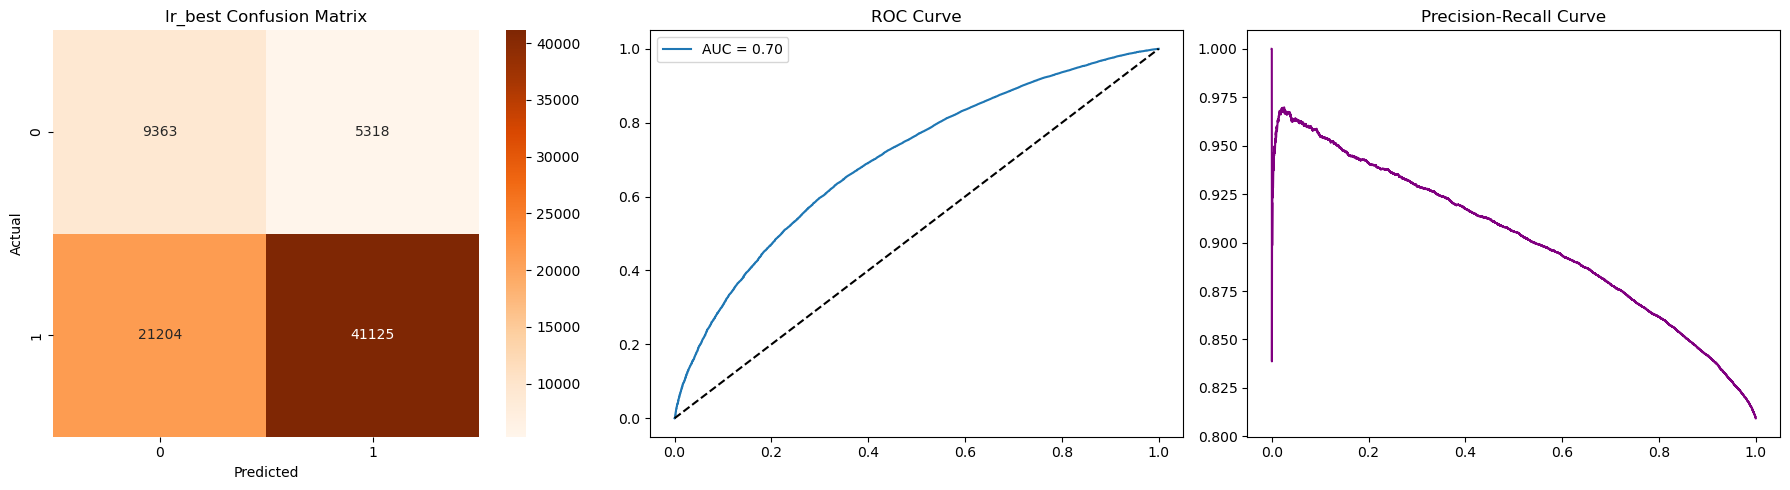

{'Model': 'lr_best',
 'ROC_AUC': 0.701223065618205,
 'Accuracy': 0.6556031684196858}

In [ ]:
evaluate_model(lr_best, X_test, y_test, model_name="lr_best")

### Decision Tree


--- dt_best Evaluation ---
ROC AUC Score: 0.6888

Classification Report:
              precision    recall  f1-score   support

           0       0.28      0.70      0.40     14681
           1       0.89      0.58      0.70     62329

    accuracy                           0.60     77010
   macro avg       0.59      0.64      0.55     77010
weighted avg       0.77      0.60      0.64     77010



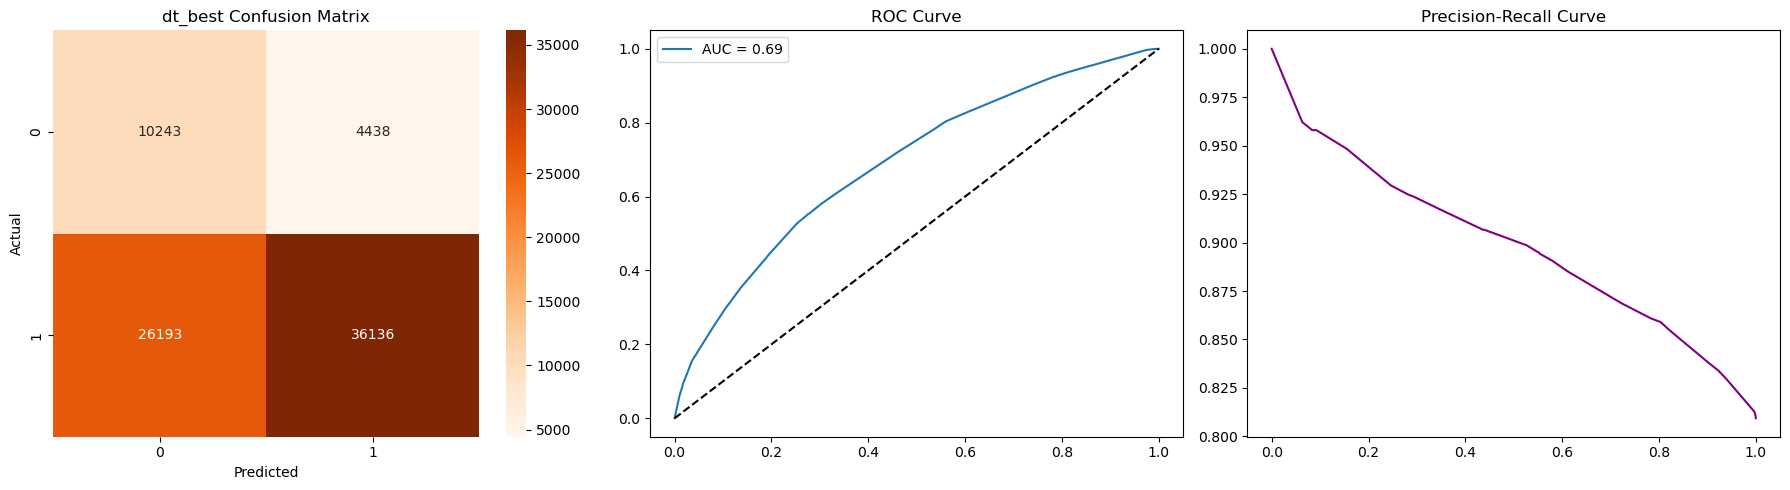

{'Model': 'dt_best',
 'ROC_AUC': 0.6887971451337628,
 'Accuracy': 0.6022464614985067}

In [ ]:
evaluate_model(dt_best, X_test, y_test, model_name="dt_best")

### Random Forest


--- rf_best Evaluation ---
ROC AUC Score: 0.7124

Classification Report:
              precision    recall  f1-score   support

           0       0.31      0.64      0.42     14681
           1       0.89      0.67      0.76     62329

    accuracy                           0.66     77010
   macro avg       0.60      0.65      0.59     77010
weighted avg       0.78      0.66      0.70     77010



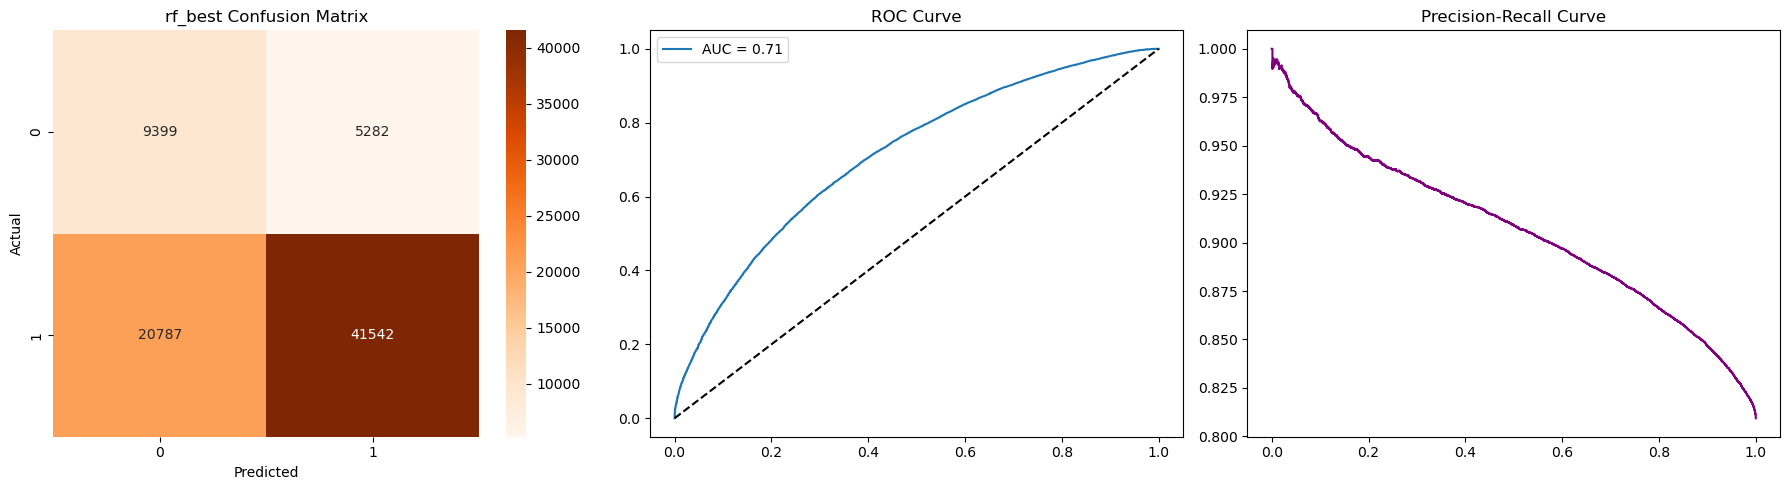

{'Model': 'rf_best',
 'ROC_AUC': 0.7124353174362434,
 'Accuracy': 0.6614855213608622}

In [ ]:
evaluate_model(rf_best, X_test, y_test, model_name="rf_best")

### Gradient Boosting


--- gbrt_best Evaluation ---
ROC AUC Score: 0.7226

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.09      0.16     14681
           1       0.82      0.99      0.90     62329

    accuracy                           0.82     77010
   macro avg       0.73      0.54      0.53     77010
weighted avg       0.79      0.82      0.76     77010



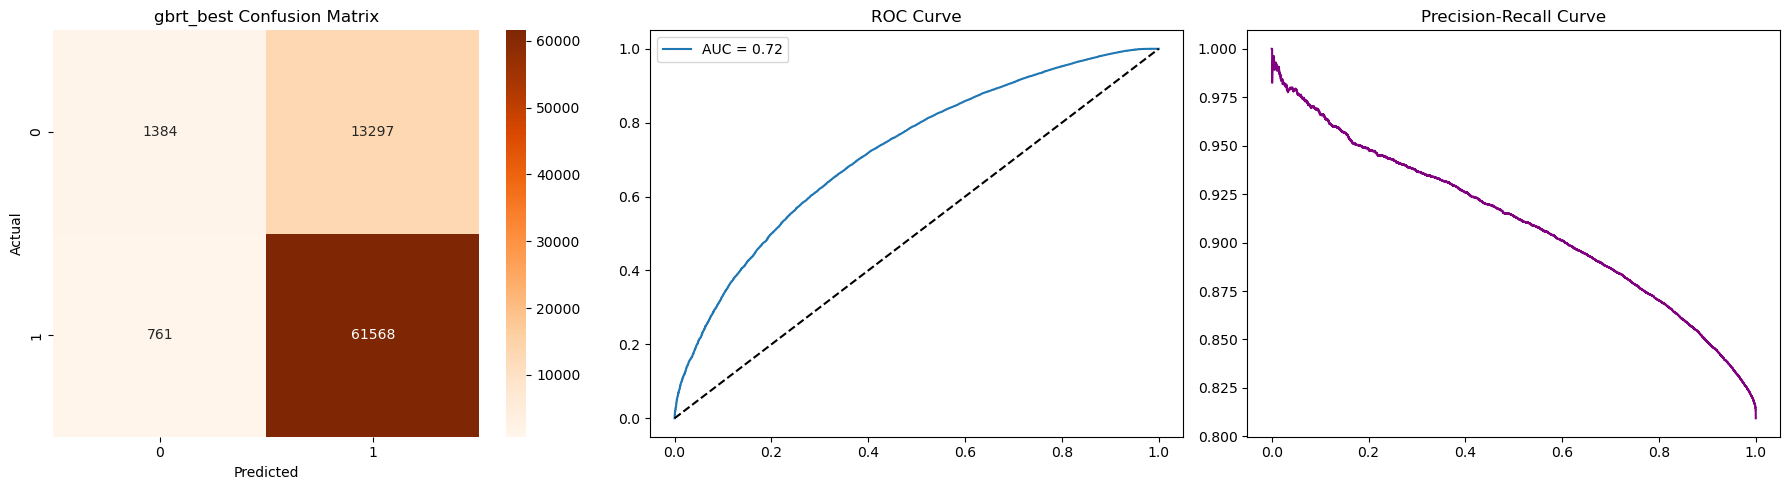

{'Model': 'gbrt_best',
 'ROC_AUC': 0.7225732729876658,
 'Accuracy': 0.817452278924815}

In [ ]:
evaluate_model(gbrt_best, X_test, y_test, model_name="gbrt_best")

### XGBoost


--- xgb_clf_best Evaluation ---
ROC AUC Score: 0.7234

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.09      0.16     14681
           1       0.82      0.99      0.90     62329

    accuracy                           0.82     77010
   macro avg       0.73      0.54      0.53     77010
weighted avg       0.79      0.82      0.76     77010



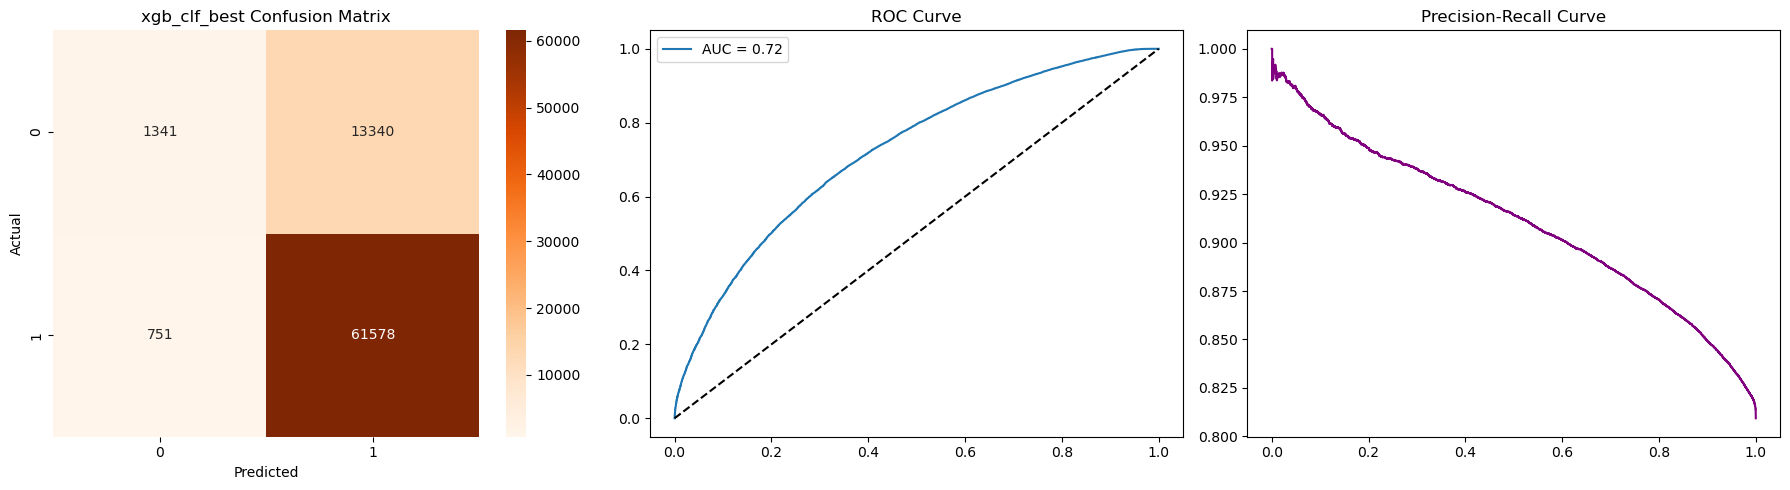

{'Model': 'xgb_clf_best',
 'ROC_AUC': 0.7234173293458195,
 'Accuracy': 0.8170237631476431}

In [ ]:
evaluate_model(xgb_clf_best, X_test, y_test, model_name="xgb_clf_best")

# **Observation**
The best model is Random Forest Model with parameters 'max_depth': 10, 'max_features': 'sqrt', 'n_estimators': 200.

Random Forest's ROC AUC Score: 0.7124


According to ROC AUC score, XGBoost model is the best model with parameters 'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 0.8.

However, it's worrying that f1 score for class 0 is very low in this model, meaning that it predicts almost everything as 1. If we consider class imbalance it might be useful to look at minumum F1-score across classes.

Random Forest with parameters 'max_depth': 10, 'max_features': 'sqrt', 'n_estimators': 200 has the best minimum F1-score across classes. Given that ROC -AUC Score of Random Forest is very close to XGBoost and it's minimum F1-score is a lot better than XGBoost, that's why we selected Random Forest as the best model

The best ROC AUC Score is : XGBoost 0.723